In [1]:
from google.colab import files
upload = files.upload()

Saving superstore_sales_prediction.csv to superstore_sales_prediction.csv


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("superstore_sales_prediction.csv", encoding="cp1252")

print("Dataset loaded successfully!")
print(df.shape)

Dataset loaded successfully!
(51290, 24)


In [3]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
0,42433,AG-2011-2040,1/1/2011,6/1/2011,Standard Class,TB-11280,Toby Braunhardt,Consumer,Constantine,Constantine,...,OFF-TEN-10000025,Office Supplies,Storage,"Tenex Lockers, Blue",408.300,2,0.0,106.140,35.46,Medium
1,22253,IN-2011-47883,1/1/2011,8/1/2011,Standard Class,JH-15985,Joseph Holt,Consumer,Wagga Wagga,New South Wales,...,OFF-SU-10000618,Office Supplies,Supplies,"Acme Trimmer, High Speed",120.366,3,0.1,36.036,9.72,Medium
2,48883,HU-2011-1220,1/1/2011,5/1/2011,Second Class,AT-735,Annie Thurman,Consumer,Budapest,Budapest,...,OFF-TEN-10001585,Office Supplies,Storage,"Tenex Box, Single Width",66.120,4,0.0,29.640,8.17,High
3,11731,IT-2011-3647632,1/1/2011,5/1/2011,Second Class,EM-14140,Eugene Moren,Home Office,Stockholm,Stockholm,...,OFF-PA-10001492,Office Supplies,Paper,"Enermax Note Cards, Premium",44.865,3,0.5,-26.055,4.82,High
4,22255,IN-2011-47883,1/1/2011,8/1/2011,Standard Class,JH-15985,Joseph Holt,Consumer,Wagga Wagga,New South Wales,...,FUR-FU-10003447,Furniture,Furnishings,"Eldon Light Bulb, Duo Pack",113.670,5,0.1,37.770,4.70,Medium


In [5]:
print(df.columns.tolist())

['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'City', 'State', 'Country', 'Postal Code', 'Market', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit', 'Shipping Cost', 'Order Priority']


In [6]:
data = df[
    [
        "Row ID",
        "Customer Name",
        "Segment",
        "State",
        "Product Name",
        "Sales",
        "Profit",
        "Shipping Cost",
        "Order Priority"
    ]
].copy()

data.rename(
    columns={"Order Priority": "Priority"},
    inplace=True
)

data.head()

,Row ID,Customer Name,Segment,State,Product Name,Sales,Profit,Shipping Cost,Priority
0,42433,Toby Braunhardt,Consumer,Constantine,"Tenex Lockers, Blue",408.300,106.140,35.46,Medium
1,22253,Joseph Holt,Consumer,New South Wales,"Acme Trimmer, High Speed",120.366,36.036,9.72,Medium
2,48883,Annie Thurman,Consumer,Budapest,"Tenex Box, Single Width",66.120,29.640,8.17,High
3,11731,Eugene Moren,Home Office,Stockholm,"Enermax Note Cards, Premium",44.865,-26.055,4.82,High
4,22255,Joseph Holt,Consumer,New South Wales,"Eldon Light Bulb, Duo Pack",113.670,37.770,4.70,Medium


In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         51290 non-null  int64  
 1   Customer Name  51290 non-null  object 
 2   Segment        51290 non-null  object 
 3   State          51290 non-null  object 
 4   Product Name   51290 non-null  object 
 5   Sales          51290 non-null  float64
 6   Profit         51290 non-null  float64
 7   Shipping Cost  51290 non-null  float64
 8   Priority       51290 non-null  object 
dtypes: float64(3), int64(1), object(5)
memory usage: 3.5+ MB


In [8]:
data.describe()

,Row ID,Sales,Profit,Shipping Cost
count,51290.00000,51290.000000,51290.000000,51290.000000
mean,25645.50000,246.490581,28.610982,26.375915
std,14806.29199,487.565361,174.340972,57.296804
min,1.00000,0.444000,-6599.978000,0.000000
25%,12823.25000,30.758625,0.000000,2.610000
50%,25645.50000,85.053000,9.240000,7.790000
75%,38467.75000,251.053200,36.810000,24.450000
max,51290.00000,22638.480000,8399.976000,933.570000


In [10]:
data.isnull().sum()

,0
Row ID,0
Customer Name,0
Segment,0
State,0
Product Name,0
Sales,0
Profit,0
Shipping Cost,0
Priority,0


In [12]:
print("Duplicate rows:",
data.duplicated().sum())

Duplicate rows: 0


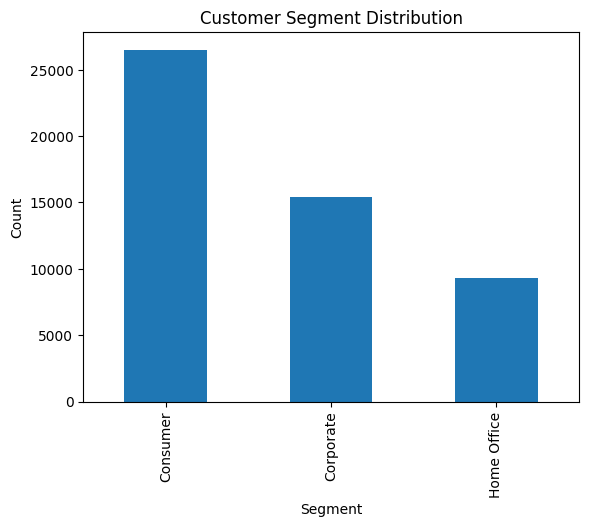

In [13]:
data["Segment"].value_counts().plot(kind="bar")

plt.title("Customer Segment Distribution")
plt.xlabel("Segment")
plt.ylabel("Count")
plt.show()

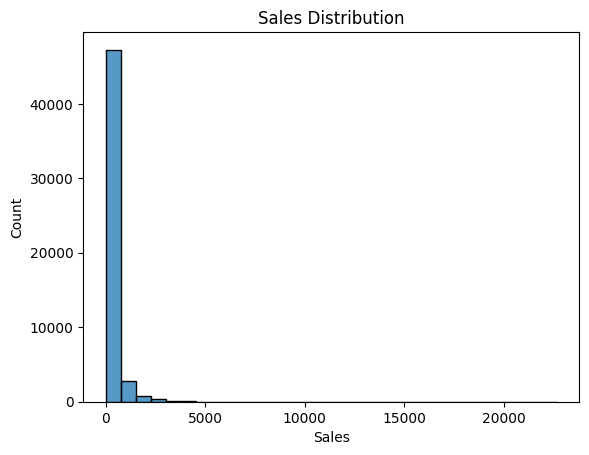

In [14]:
sns.histplot(data=data, x="Sales", bins=30)

plt.title("Sales Distribution")
plt.show()

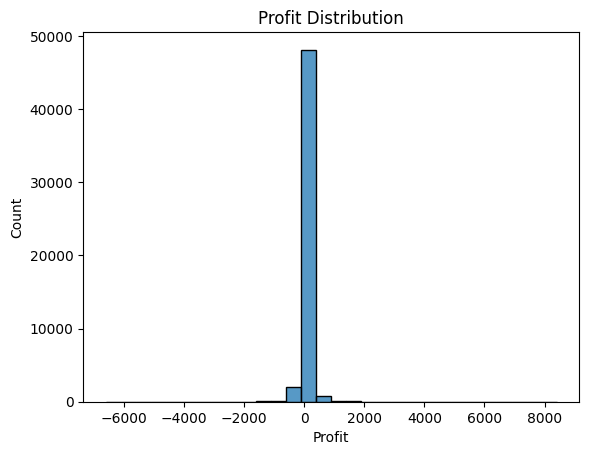

In [15]:
sns.histplot(data=data, x="Profit", bins=30)

plt.title("Profit Distribution")
plt.show()

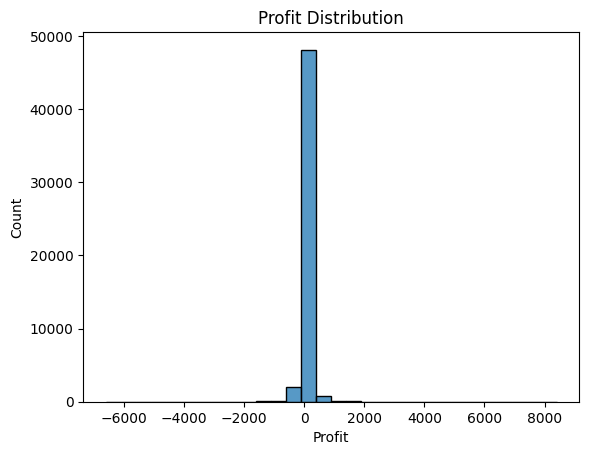

In [16]:
sns.histplot(data=data, x="Profit", bins=30)

plt.title("Profit Distribution")
plt.show()

In [17]:
top_products = (
    data.groupby("Product Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)

Product Name
Apple Smart Phone, Full Size                                86935.7786
Cisco Smart Phone, Full Size                                76441.5306
Motorola Smart Phone, Full Size                             73156.3030
Nokia Smart Phone, Full Size                                71904.5555
Canon imageCLASS 2200 Advanced Copier                       61599.8240
Hon Executive Leather Armchair, Adjustable                  58193.4841
Office Star Executive Leather Armchair, Adjustable          50661.6840
Harbour Creations Executive Leather Armchair, Adjustable    50121.5160
Samsung Smart Phone, Cordless                               48653.4600
Nokia Smart Phone, with Caller ID                           47877.7857
Name: Sales, dtype: float64


In [18]:
print("Dataset Shape:", data.shape)
print("Total Sales:", data["Sales"].sum())
print("Total Profit:", data["Profit"].sum())
print("Missing Values:", data.isnull().sum().sum())

Dataset Shape: (51290, 9)
Total Sales: 12642501.90988
Total Profit: 1467457.2912800002
Missing Values: 0


In [20]:
print(data["Segment"].value_counts())

Segment
Consumer       26518
Corporate      15429
Home Office     9343
Name: count, dtype: int64


In [21]:
print("Total Sales:", data["Sales"].sum())
print("Total Profit:", data["Profit"].sum())
print("Average Sales:", data["Sales"].mean())
print("Average Profit:", data["Profit"].mean())

Total Sales: 12642501.90988
Total Profit: 1467457.2912800002
Average Sales: 246.4905812025736
Average Profit: 28.610982477675964


State
England                   485170.9710
California                457687.6315
Ile-de-France             317822.5440
New York                  310876.2710
New South Wales           270487.1040
Queensland                238312.7340
North Rhine-Westphalia    216451.8510
Texas                     170188.0458
San Salvador              153639.3970
National Capital          152175.3555
Name: Sales, dtype: float64


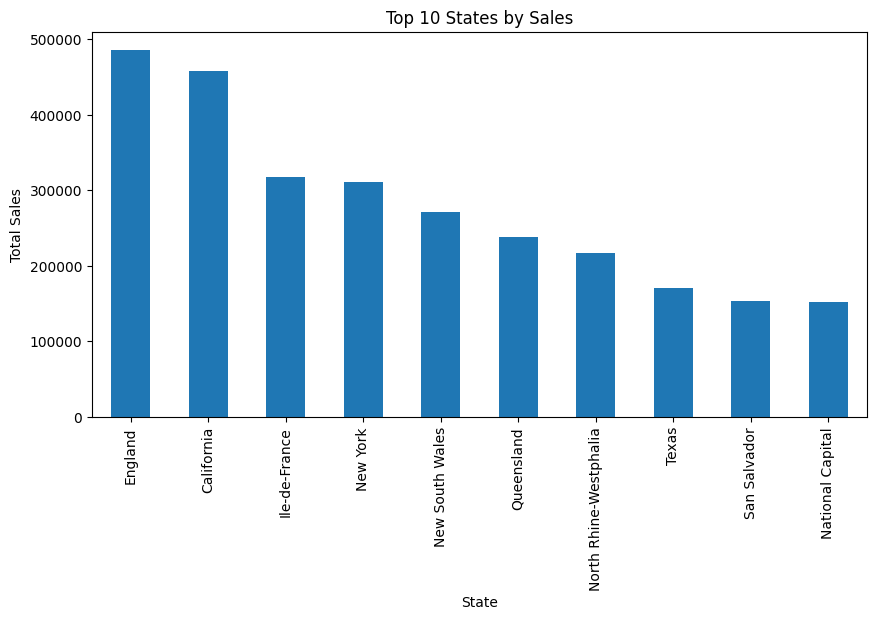

In [22]:
top_states = data.groupby("State")["Sales"].sum().nlargest(10)

print(top_states)

top_states.plot(kind="bar", figsize=(10, 5))
plt.title("Top 10 States by Sales")
plt.xlabel("State")
plt.ylabel("Total Sales")
plt.show()

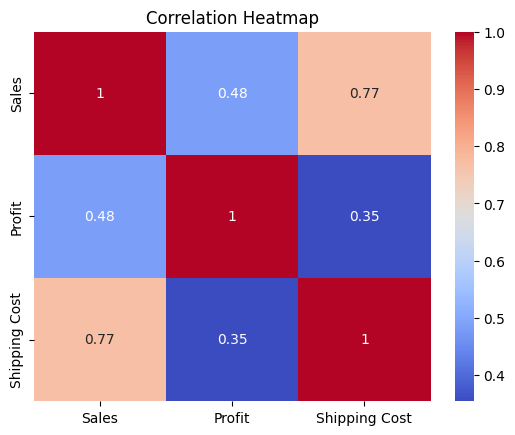

In [23]:
sns.heatmap(
    data[["Sales", "Profit", "Shipping Cost"]].corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

In [24]:
print("Number of Rows:", data.shape[0])
print("Number of Columns:", data.shape[1])
print("Missing Values:", data.isnull().sum().sum())
print("Duplicate Rows:", data.duplicated().sum())
print("Unique Customers:", data["Customer Name"].nunique())
print("Unique Products:", data["Product Name"].nunique())

Number of Rows: 51290
Number of Columns: 9
Missing Values: 0
Duplicate Rows: 0
Unique Customers: 795
Unique Products: 3788


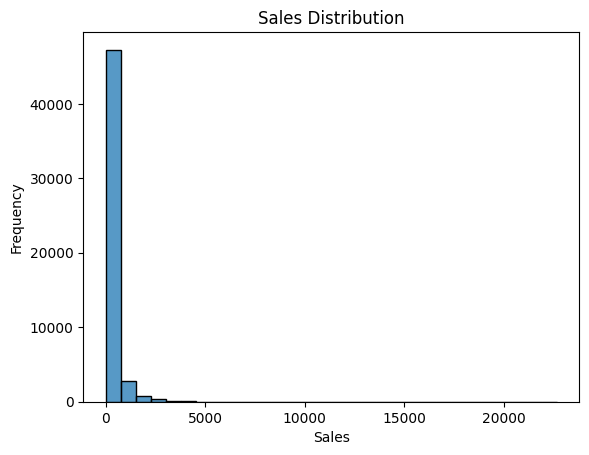

In [25]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.histplot(data=data, x="Sales", bins=30)

plt.title("Sales Distribution")
plt.xlabel("Sales")
plt.ylabel("Frequency")
plt.show()

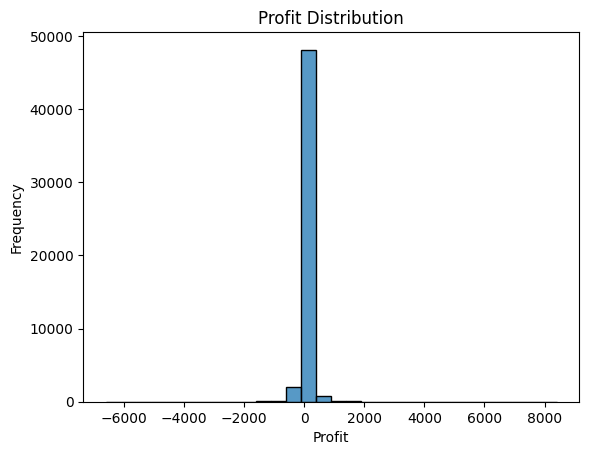

In [26]:
sns.histplot(data=data, x="Profit", bins=30)

plt.title("Profit Distribution")
plt.xlabel("Profit")
plt.ylabel("Frequency")
plt.show()

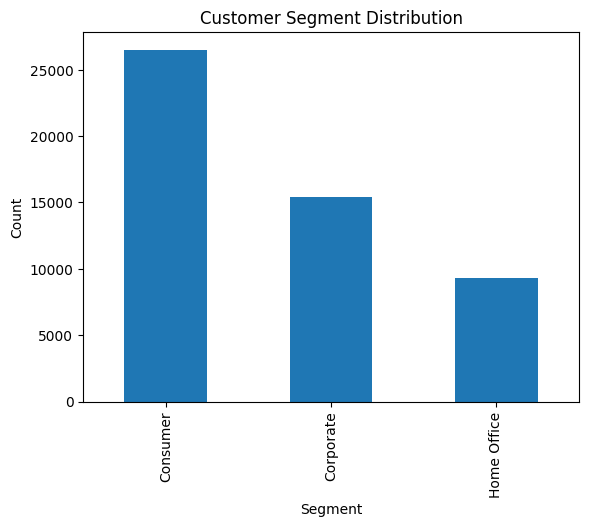

In [27]:
data["Segment"].value_counts().plot(kind="bar")

plt.title("Customer Segment Distribution")
plt.xlabel("Segment")
plt.ylabel("Count")
plt.show()

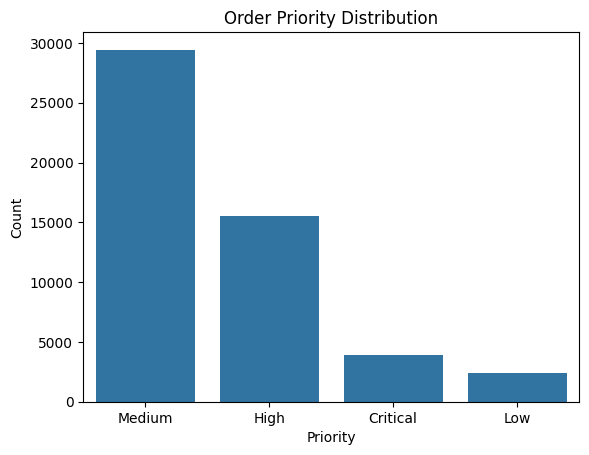

In [28]:
sns.countplot(data=data, x="Priority")

plt.title("Order Priority Distribution")
plt.xlabel("Priority")
plt.ylabel("Count")
plt.show()